# Bassac River Forecasting — Part 2: Station Calibration & Feature Engineering

Calibrates Koh Khel onto the Koh Thum scale (2020–2023 overlap), merges all 4 daily tables, builds 10 leak-free features, and verifies zero leakage.

In [1]:
# Setup & load cleaned daily tables
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED_DIR = Path('..').resolve() / 'data' / 'processed'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

bassac = pd.read_csv(PROCESSED_DIR / 'bassac_daily.csv', parse_dates=['date']).sort_values('date')
kohkhel = pd.read_csv(PROCESSED_DIR / 'kohkhel_daily.csv', parse_dates=['date']).sort_values('date')
glofas = pd.read_csv(PROCESSED_DIR / 'glofas_daily.csv', parse_dates=['date']).sort_values('date')
rainfall = pd.read_csv(PROCESSED_DIR / 'nasa_rain_daily.csv', parse_dates=['date']).sort_values('date')

print('Loaded tables:', len(bassac), 'bassac |', len(kohkhel), 'kohkhel |', len(glofas), 'glofas |', len(rainfall), 'rainfall')


Loaded tables: 1438 bassac | 1511 kohkhel | 2353 glofas | 2363 rainfall


In [2]:
# Fit station calibration on 2020 - 2023 overlap (no 2024 - 2026 leakage)
overlap = bassac.dropna(subset=['WL']).merge(kohkhel, on='date', how='inner')
correlation_r = overlap['WL'].corr(overlap['WL_raw'])
slope, intercept = np.polyfit(overlap['WL_raw'], overlap['WL'], 1)
overlap['WL_calibrated'] = slope * overlap['WL_raw'] + intercept

mae_before = (overlap['WL_raw'] - overlap['WL']).abs().mean()
mae_after = (overlap['WL_calibrated'] - overlap['WL']).abs().mean()

print(f'Shared days (2020-2023): {len(overlap)}')
print(f'Correlation (r)        : {correlation_r:.4f}')
print(f'Calibration formula    : WL = {slope:.4f} * WL_raw + ({intercept:.4f})')
print(f'Average gap (MAE)      : {mae_before:.3f} m -> {mae_after:.3f} m')


Shared days (2020-2023): 643
Correlation (r)        : 0.9957
Calibration formula    : WL = 0.7942 * WL_raw + (-0.4756)
Average gap (MAE)      : 1.482 m -> 0.093 m


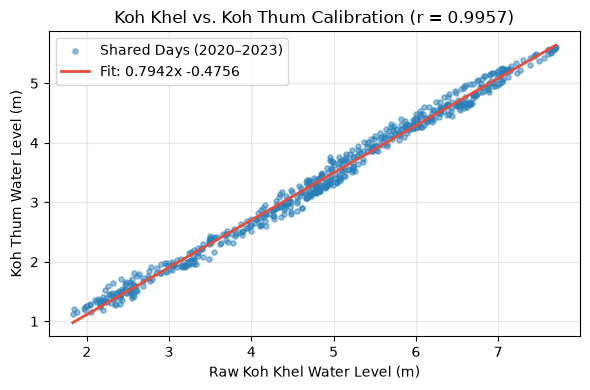

In [3]:
# Figure 1A: Calibration scatter plot (2020 - 2023 shared days)
x_line = np.linspace(overlap['WL_raw'].min(), overlap['WL_raw'].max(), 100)

plt.figure(figsize=(6, 4))
plt.scatter(overlap['WL_raw'], overlap['WL'], alpha=0.5, s=14, color='#2980b9', label='Shared Days (2020–2023)')
plt.plot(x_line, slope * x_line + intercept, color='#e74c3c', linewidth=2, label=f'Fit: {slope:.4f}x {intercept:+.4f}')
plt.title(f'Koh Khel vs. Koh Thum Calibration (r = {correlation_r:.4f})')
plt.xlabel('Raw Koh Khel Water Level (m)')
plt.ylabel('Koh Thum Water Level (m)')
plt.legend()
plt.tight_layout()
plt.show()


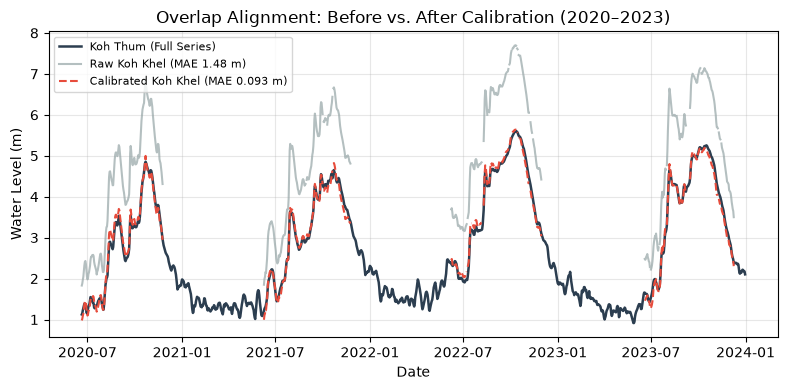

In [4]:
# Figure 1B: Overlap alignment before vs. after calibration (2020 - 2023)
overlap_daily = overlap.set_index('date')[['WL', 'WL_raw', 'WL_calibrated']].asfreq('D')
bassac_full_line = bassac[bassac['date'] <= '2023-12-31'].set_index('date')['WL'].asfreq('D')

plt.figure(figsize=(8, 4))
plt.plot(bassac_full_line.index, bassac_full_line.values, label='Koh Thum (Full Series)', color='#2c3e50', linewidth=1.8)
plt.plot(overlap_daily.index, overlap_daily['WL_raw'], label=f'Raw Koh Khel (MAE {mae_before:.2f} m)', color='#95a5a6', alpha=0.7)
plt.plot(overlap_daily.index, overlap_daily['WL_calibrated'], label=f'Calibrated Koh Khel (MAE {mae_after:.3f} m)', color='#e74c3c', linestyle='--')
plt.title('Overlap Alignment: Before vs. After Calibration (2020–2023)')
plt.xlabel('Date')
plt.ylabel('Water Level (m)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [5]:
# Stitch 2020 - 2026 water level & join discharge + rainfall
part_2020_2024 = bassac[['date', 'WL']].copy()
part_2020_2024['station_source'] = 'Koh_Thum'

part_2024_2026 = kohkhel[kohkhel['date'] >= '2024-07-01'].copy()
part_2024_2026['WL'] = slope * part_2024_2026['WL_raw'] + intercept
part_2024_2026['station_source'] = 'Koh_Khel_Calibrated'
part_2024_2026 = part_2024_2026[['date', 'WL', 'station_source']]

combined_wl = pd.concat([part_2020_2024, part_2024_2026], ignore_index=True)

# Create full daily calendar and merge each table step by step
end_date = min(combined_wl['date'].max(), glofas['date'].max(), rainfall['date'].max())
daily_table = pd.DataFrame({'date': pd.date_range(combined_wl['date'].min(), end_date, freq='D')})
daily_table = daily_table.merge(combined_wl, on='date', how='left')
daily_table = daily_table.merge(glofas[['date', 'upstream_discharge']], on='date', how='left')
daily_table = daily_table.merge(rainfall[['date', 'rain_mm']], on='date', how='left')
daily_table = daily_table.sort_values('date').reset_index(drop=True)

print('Unified daily table:', daily_table.shape)


Unified daily table: (2335, 5)


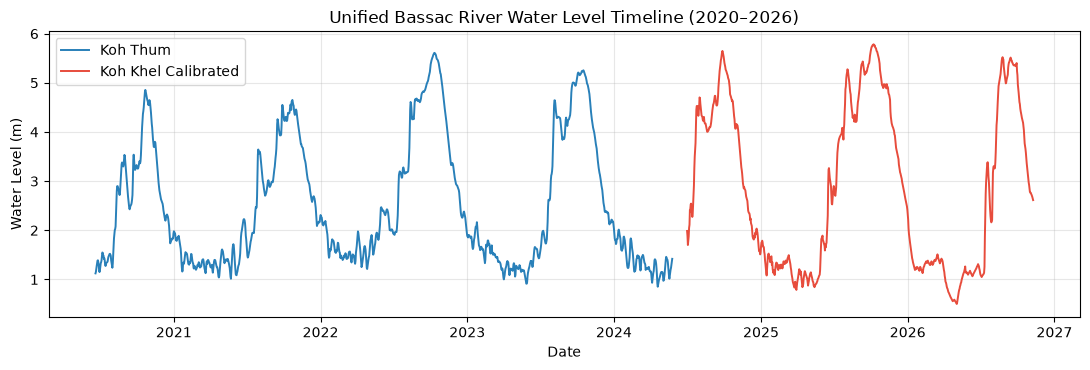

In [6]:
# Figure 2: Plot unified 2020 - 2026 water level timeline
fig, ax = plt.subplots(figsize=(11, 3.8))
for src_name, color in [('Koh_Thum', '#2980b9'), ('Koh_Khel_Calibrated', '#e74c3c')]:
    sub = daily_table[daily_table['station_source'] == src_name].set_index('date')['WL'].asfreq('D')
    ax.plot(sub.index, sub.values, label=src_name.replace('_', ' '), color=color, linewidth=1.4)
ax.set_title('Unified Bassac River Water Level Timeline (2020–2026)')
ax.set_xlabel('Date')
ax.set_ylabel('Water Level (m)')
ax.legend()
plt.tight_layout()
plt.show()


In [7]:
# Build 10 past-only features & 1-day-ahead target (WL_next)
FEATURE_COLS = [
    'WL', 'WL_lag1', 'WL_lag2', 'WL_lag3', 'WL_diff',
    'upstream_discharge_lag1', 'upstream_discharge_diff',
    'rain_mm', 'rain_lag1', 'rain_3d'
]
TARGET_COL = 'WL_next'

df_feat = daily_table.copy()
df_feat['WL_lag1'] = df_feat['WL'].shift(1)
df_feat['WL_lag2'] = df_feat['WL'].shift(2)
df_feat['WL_lag3'] = df_feat['WL'].shift(3)
df_feat['WL_diff'] = df_feat['WL'] - df_feat['WL_lag1']

df_feat['upstream_discharge_lag1'] = df_feat['upstream_discharge'].shift(1)
df_feat['upstream_discharge_diff'] = df_feat['upstream_discharge'] - df_feat['upstream_discharge_lag1']

df_feat['rain_lag1'] = df_feat['rain_mm'].shift(1)
df_feat['rain_3d'] = df_feat['rain_mm'].rolling(3).sum()

df_feat[TARGET_COL] = df_feat['WL'].shift(-1)

# Drop boundary rows around edges and June 2024 station gap
modeling_table = df_feat.dropna(subset=FEATURE_COLS + [TARGET_COL]).reset_index(drop=True)
modeling_table = modeling_table[['date', 'station_source'] + FEATURE_COLS + [TARGET_COL]]
modeling_table.to_csv(PROCESSED_DIR / 'modeling_table.csv', index=False)

print('Saved modeling_table.csv:', modeling_table.shape)
print(modeling_table.head())


Saved modeling_table.csv: (2285, 13)
        date station_source        WL   WL_lag1   WL_lag2   WL_lag3   WL_diff  \
0 2020-06-23       Koh_Thum  1.273958  1.222813  1.153125  1.123438  0.051146   
1 2020-06-24       Koh_Thum  1.331354  1.273958  1.222813  1.153125  0.057396   
2 2020-06-25       Koh_Thum  1.382708  1.331354  1.273958  1.222813  0.051354   
3 2020-06-26       Koh_Thum  1.389583  1.382708  1.331354  1.273958  0.006875   
4 2020-06-27       Koh_Thum  1.354688  1.389583  1.382708  1.331354 -0.034896   

   upstream_discharge_lag1  upstream_discharge_diff  rain_mm  rain_lag1  \
0                  6917.31                  -652.17     1.38       2.54   
1                  6265.14                  -445.11    14.84       1.38   
2                  5820.03                  -261.99     7.78      14.84   
3                  5558.04                  -176.34    17.60       7.78   
4                  5381.70                  -218.54     7.36      17.60   

   rain_3d   WL_next  
0 

In [8]:
# Simple checks: no missing values and dates are strictly in order
print('Missing values in features/target:', int(modeling_table[FEATURE_COLS + [TARGET_COL]].isna().sum().sum()))
print('Dates sorted oldest to newest    :', modeling_table['date'].is_monotonic_increasing)
print('First date                       :', modeling_table['date'].min().date())
print('Last date                        :', modeling_table['date'].max().date())


Missing values in features/target: 0
Dates sorted oldest to newest    : True
First date                       : 2020-06-23
Last date                        : 2026-11-08
